# Figure 5 extras (moved out of `figure5_immunotherapy.ipynb`, 2026-10-26)

Not part of the figure. Run the setup cell first; each later section has its own setup cell.

- **Explorations**: type-1 sniffer slingshot vs normal, single slingshot trace, cases 1–4 with cancer dynamics
- **Parameter scans** (type-1 IFFL + cancer, from `figure_iffl_v2`)
- **Type-2 IFFL with general parameters** (from `figure_iffl_v3`)

Exports are prefixed `figure5_old_` so they never overwrite the main figure's PDFs.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from rpa_control.paths import save_fig

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Explorations (not in the figure)

Earlier versions and variants of the panels above: type-1 IFFL (`sniffer_rhs`) slingshot vs normal, a single slingshot trace, and cases 1–4 with cancer dynamics (kernels $(B-\mu)^+$ and $(B-\mu)^3$, time to progression, $\int(B-\mu)^3$).

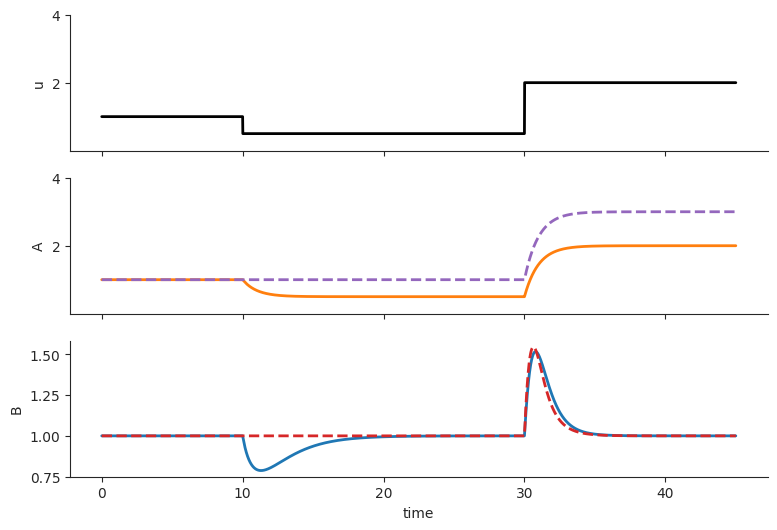

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_A.pdf


In [2]:
# ── Fold-change detector ─────────────────────────────────────────────
# dA/dt = X - A      (A tracks X)
# dB/dt = X/A - B    (B senses X/A; B* = 1 at any X)
def fcd_rhs(t, state, X_of_t):
    A, B = state
    X = X_of_t(t)
    return [X - A, X / A - B]

def sniffer_rhs(t, state, X_of_t):
    A, B = state
    X = X_of_t(t)
    # dA/dt = X - A
    # dB/dt = X - A*B
    return [X - A, X - A * B]

# Piecewise alpha: 1 → 0.5 → 0.25
t1, t2, t_end = 10.0, 30.0, 45.0

def u_of_t_slingshot(t):
    if t < t1: return 1.0
    elif t < t2: return 0.5
    return 2.0

def u_of_t_normal(t):
    if t < t2: return 1.0
    return 3.0

t = np.linspace(0, t_end, 6000)
A0, B0 = 1.0, 1.0
sol_slingshot = solve_ivp(sniffer_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_slingshot,), max_step=0.05, rtol=1e-8, atol=1e-10)
A_sling = sol_slingshot.y[0]
B_sling = sol_slingshot.y[1]


sol_normal = solve_ivp(sniffer_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_normal,), max_step=0.05, rtol=1e-8, atol=1e-10)
A_normal = sol_normal.y[0]
B_normal = sol_normal.y[1]

# ── Plot ─────────────────────────────────────────────────────────────
# fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(4.5, 3), sharex=True)
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 6), sharex=True)

# u:    
ax = axes[0]
lw = 2
# for segment in [(0, t1), (t1, t2), (t2, t_end)]:
#     ax.plot(segment, [const_u(segment[0]+0.01), const_u(segment[1]-0.01)], lw=lw, color='k')
ax.plot(t, [u_of_t_slingshot(ti) for ti in t], lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

# A:
ax = axes[1]
ax.plot(t, A_sling, lw=lw, color='C1')
ax.plot(t, A_normal, lw=lw, color='C4', ls='--')
ax.set_ylabel('A')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

# B:
ax = axes[2]
ax.plot(t, B_sling, lw=lw, color='C0')
ax.plot(t, B_normal, lw=lw, color='C3', ls='--')
ax.set_ylabel('B')
ax.set_xlabel('time')


for ax in axes:
    sns.despine(ax=ax)

plt.show()

save_fig(fig, 'figure5_old_sniffer_slingshot_vs_normal.pdf')

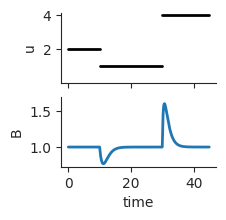

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_C.pdf


In [3]:


# ── Fold-change detector ─────────────────────────────────────────────
# dA/dt = X - A      (A tracks X)
# dB/dt = X/A - B    (B senses X/A; B* = 1 at any X)
def fcd_rhs(t, state, X_of_t):
    A, B = state
    X = X_of_t(t)
    return [X - A, X / A - B]

# Piecewise X: 1 → 2 → 4
t1, t2, t_end = 10.0, 30.0, 45.0
def u_of_t_slingshot(t):
    if t < t1: return 2.0
    if t < t2: return 1.0
    return 4.0

t = np.linspace(0, t_end, 6000)
A0, B0 = 2.0, 1.0
sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_slingshot,), max_step=0.05, rtol=1e-8, atol=1e-10)
A_slingshot = sol.y[0]
B_slingshot = sol.y[1]


# ── Plot ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(2, 2), sharex=True)

# u: 
ax = axes[0]
lw = 2
for segment in [(0, t1), (t1, t2), (t2, t_end)]:
    ax.plot(segment, [u_of_t_slingshot(segment[0]+0.01), u_of_t_slingshot(segment[1]-0.01)], lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

# A:
# ax = axes[1]
# ax.plot(t, A_slingshot, lw=lw, color='C1')
# ax.set_ylabel('A')
# ax.set_yticks([2, 4])

# B:
ax = axes[1]
ax.plot(t, B_slingshot, lw=lw, color='C0')

# mask = t > 30
# ax.plot(t[mask], B[mask], lw=lw, color='C0', zorder=-1, linestyle='--')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(top=1.7)

for ax in axes:
    sns.despine(ax=ax)

plt.show()


save_fig(fig, 'figure5_old_slingshot_trace.pdf')


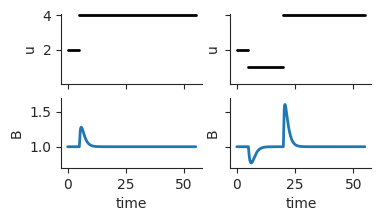

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_1_direct_vs_sensitized_uB.pdf
1.4595618068704355
Time to progression (direct): 33.89481580263377
Time to progression (slingshot): 49.471578596432735


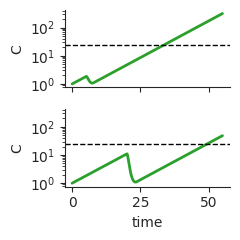

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_1_direct_vs_sensitized_C.pdf


In [6]:
# Add C dynamics: dC/dt = C * (c1 - c2 * max(B - mu, 0))
t1, t2, t_end = 5.0, 20.0, 55.0
c1, c2, mu = 0.12, 3, 1.1
C0 = 1.0


def integrate_C(t, B):
    def f(tt, C):
        B_t = np.interp(tt, t, B)
        return C[0] * (c1 - c2 * max(B_t - mu, 0.0))
    sol = solve_ivp(f, [t[0], t[-1]], [C0], t_eval=t,
                    max_step=0.05, rtol=1e-8, atol=1e-10)
    return sol.y[0]


# ── Simulate both cases ──────────────────────────────────────────────
def u_of_t_direct(t):
    if t < t1: return 2.0
    return 4.0

def u_of_t_slingshot(t):
    if t < t1: return 2.0
    if t < t2: return 1.0
    return 4.0

t = np.linspace(0, t_end, 6000)
A0, B0 = 2.0, 1.0

sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_direct,), max_step=0.05,
                rtol=1e-8, atol=1e-10)
B_direct = sol.y[1]
C_direct = integrate_C(t, B_direct)

sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_slingshot,), max_step=0.05,
                rtol=1e-8, atol=1e-10)
B_slingshot = sol.y[1]
C_slingshot = integrate_C(t, B_slingshot)


# ── Figure 1: u and B (2×2) ─────────────────────────────────────────
fig_uB, axes = plt.subplots(nrows=2, ncols=2, figsize=(4, 2),
                            sharex=True, sharey='row')

lw = 2

# Left: direct
ax = axes[0, 0]
for segment in [(0, t1), (t1, t_end)]:
    ax.plot(segment,
            [u_of_t_direct(segment[0] + 0.01),
             u_of_t_direct(segment[1] - 0.01)],
            lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

ax = axes[1, 0]
ax.plot(t, B_direct, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(bottom=0.7, top=1.7)

# Right: slingshot
ax = axes[0, 1]
for segment in [(0, t1), (t1, t2), (t2, t_end)]:
    ax.plot(segment,
            [u_of_t_slingshot(segment[0] + 0.01),
             u_of_t_slingshot(segment[1] - 0.01)],
            lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

ax = axes[1, 1]
ax.plot(t, B_slingshot, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(bottom=0.7, top=1.7)

for ax in axes.flatten():
    sns.despine(ax=ax)

plt.show()

save_fig(fig_uB, 'figure5_old_case1_standard_vs_slingshot_uB.pdf')


# ── Figure 2: C only (1×2) ──────────────────────────────────────────
fig_C, axes_C = plt.subplots(nrows=2, ncols=1, figsize=(2.5, 2.5),
                             sharex=True, sharey=True)

TTP_THRESHOLD = 25

ax = axes_C[0]
ax.plot(t, C_direct, lw=lw, color='C2')
ax.set_ylabel('C')
ax.set_xlabel('time')
ax.axhline(TTP_THRESHOLD, color='k', linestyle='--', lw=1)
ax.set_yscale('log')

ax = axes_C[1]
ax.plot(t, C_slingshot, lw=lw, color='C2')
ax.set_ylabel('C')
ax.set_xlabel('time')
ax.axhline(TTP_THRESHOLD, color='k', linestyle='--', lw=1)
ax.set_yscale('log')

for ax in axes_C:
    sns.despine(ax=ax)


axes_C[0].set_xlabel('')

plt.tight_layout()

# cancer time to progression
TTP_direct = t[C_direct > TTP_THRESHOLD][0] if any(C_direct > TTP_THRESHOLD) else np.nan
TTP_slingshot = t[C_slingshot > TTP_THRESHOLD][0] if any(C_slingshot > TTP_THRESHOLD) else np.nan
print(TTP_slingshot / TTP_direct)
print(f"Time to progression (direct): {TTP_direct}")
print(f"Time to progression (slingshot): {TTP_slingshot}")

plt.show()

save_fig(fig_C, 'figure5_old_case1_standard_vs_slingshot_C.pdf')


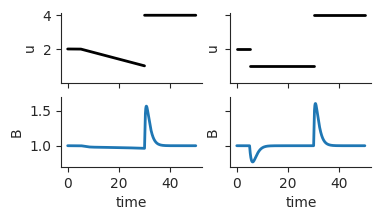

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_2_ramp_vs_sensitized_uB.pdf
nan
Time to progression (ramp): nan
Time to progression (slingshot): nan


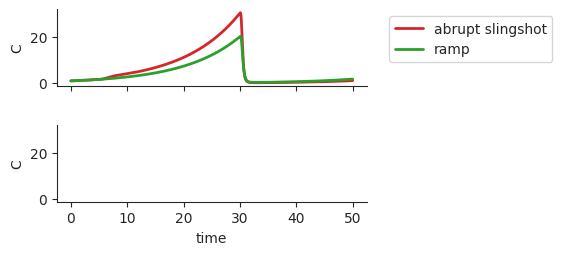

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_2_ramp_vs_sensitized_C.pdf


In [7]:
# Compare ramp-down vs abrupt slingshot, with dC/dt = C * (c1 - c2 * (B - mu)**3)
t1, t2, t_end = 5.0, 30.0, 50
c1, c2, mu = 0.1, 20, 1
C0 = 1.0


def integrate_C_cubic(t, B):
    def f(tt, C):
        B_t = np.interp(tt, t, B)
        return C[0] * (c1 - c2 * (B_t - mu) ** 3)
    sol = solve_ivp(f, [t[0], t[-1]], [C0], t_eval=t,
                    max_step=0.05, rtol=1e-8, atol=1e-10)
    return sol.y[0]


# ── Inputs ──────────────────────────────────────────────────────────
# Ramp: u stays at 2, ramps linearly 2 → 1 over [t1, t2], then jumps to 4
def u_of_t_ramp(t):
    if t < t1: return 2.0
    if t < t2: return 2.0 + (1.0 - 2.0) * (t - t1) / (t2 - t1)
    return 4.0

# Abrupt slingshot: 2 → 1 → 4
def u_of_t_slingshot(t):
    if t < t1: return 2.0
    if t < t2: return 1.0
    return 4.0


t = np.linspace(0, t_end, 6000)
A0, B0 = 2.0, 1.0

sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_ramp,), max_step=0.05,
                rtol=1e-8, atol=1e-10)
B_ramp = sol.y[1]
C_ramp = integrate_C_cubic(t, B_ramp)

sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_slingshot,), max_step=0.05,
                rtol=1e-8, atol=1e-10)
B_slingshot = sol.y[1]
C_slingshot = integrate_C_cubic(t, B_slingshot)


# ── Figure 1: u and B (2×2) ─────────────────────────────────────────
fig_uB, axes = plt.subplots(nrows=2, ncols=2, figsize=(4, 2),
                            sharex=True, sharey='row')

lw = 2

# Left: ramp
ax = axes[0, 0]
u_ramp_vals = np.array([u_of_t_ramp(tt) for tt in t])
u_plot = u_ramp_vals.copy()
u_plot[np.isclose(t, t2, atol=t[1] - t[0])] = np.nan
ax.plot(t, u_plot, lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

ax = axes[1, 0]
ax.plot(t, B_ramp, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(bottom=0.7, top=1.7)

# Right: abrupt slingshot
ax = axes[0, 1]
for segment in [(0, t1), (t1, t2), (t2, t_end)]:
    ax.plot(segment,
            [u_of_t_slingshot(segment[0] + 0.01),
             u_of_t_slingshot(segment[1] - 0.01)],
            lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

ax = axes[1, 1]
ax.plot(t, B_slingshot, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(bottom=0.7, top=1.7)

for ax in axes.flatten():
    sns.despine(ax=ax)

plt.show()

save_fig(fig_uB, 'figure5_old_case2_gradual_vs_abrupt_uB.pdf')


# ── Figure 2: C only (2 rows, stacked) ──────────────────────────────
fig_C, axes_C = plt.subplots(nrows=2, ncols=1, figsize=(4, 2.5),
                             sharex=True, sharey=True, gridspec_kw={'hspace': 0.5})

TTP_THRESHOLD = 1000

ax = axes_C[0]
ax.plot(t, C_slingshot, lw=lw, color='C3', label='abrupt slingshot')
ax.plot(t, C_ramp, lw=lw, color='C2', label='ramp')
ax.set_ylabel('C')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

ax = axes_C[1]
# ax.plot(t, C_slingshot, lw=lw, color='C2')
ax.set_ylabel('C')
ax.set_xlabel('time')


for ax in axes_C:
    sns.despine(ax=ax)
    # ax.axhline(TTP_THRESHOLD, color='k', linestyle='--', lw=1)
    # ax.set_yscale('log')

axes_C[0].set_xlabel('')


TTP_ramp = t[C_ramp > TTP_THRESHOLD][0] if any(C_ramp > TTP_THRESHOLD) else np.nan
TTP_slingshot = t[C_slingshot > TTP_THRESHOLD][0] if any(C_slingshot > TTP_THRESHOLD) else np.nan
print(TTP_slingshot / TTP_ramp)
print(f"Time to progression (ramp): {TTP_ramp}")
print(f"Time to progression (slingshot): {TTP_slingshot}")

plt.show()

save_fig(fig_C, 'figure5_old_case2_gradual_vs_abrupt_C.pdf')


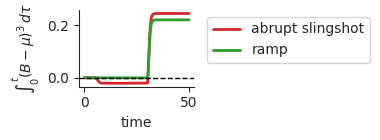

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_2_ramp_vs_sensitized_integral.pdf


In [8]:
# ── Figure 3: cumulative integral of (B - mu)**3 ────────────────────
from scipy.integrate import cumulative_trapezoid

I_ramp = cumulative_trapezoid((B_ramp - mu) ** 3, t, initial=0.0)
I_slingshot = cumulative_trapezoid((B_slingshot - mu) ** 3, t, initial=0.0)

fig_I, ax = plt.subplots(figsize=(4, 1.5))
ax.plot(t, I_slingshot, lw=lw, color='C3', label='abrupt slingshot')
ax.plot(t, I_ramp,       lw=lw, color='C2', label='ramp')
ax.axhline(0, color='k', linestyle='--', lw=1)
ax.set_xlabel('time')
ax.set_ylabel(r'$\int_0^t (B-\mu)^3\,d\tau$')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig_I, 'figure5_old_case2_gradual_vs_abrupt_integral.pdf')


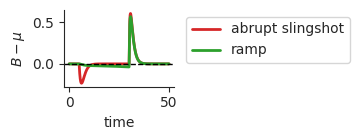

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_2_ramp_vs_sensitized_B_minus_mu.pdf


In [9]:
# ── Figure 4: B - mu over time ─────────────────────────────────────
fig_Bmu, ax = plt.subplots(figsize=(4, 1.5))
ax.plot(t, B_slingshot - mu, lw=lw, color='C3', label='abrupt slingshot')
ax.plot(t, B_ramp       - mu, lw=lw, color='C2', label='ramp')
ax.axhline(0, color='k', linestyle='--', lw=1)
ax.set_xlabel('time')
ax.set_ylabel(r'$B - \mu$')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

save_fig(fig_Bmu, 'figure5_old_case2_gradual_vs_abrupt_B_minus_mu.pdf')


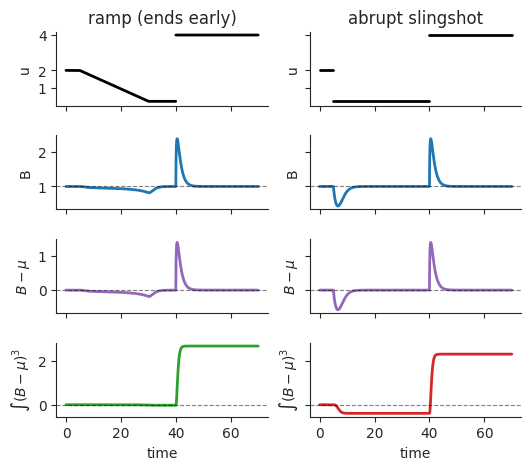

final integral (ramp):       -53.417
final integral (slingshot): -46.051
Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_3_ramp_ends_early.pdf


In [10]:
# Ramp ends before t2 so B re-equilibrates to u=1 before the jump
t1, t2, t_end = 5.0, 40.0, 70.0
t_ramp_end = t2 - 10.0  # ramp finishes here, then u stays at 1 until t2
c1, c2, mu = 0.1, 20, 1
C0 = 1.0
A0, B0 = 2.0, 1.0


def integrate_C_cubic(t, B):
    def f(tt, C):
        B_t = np.interp(tt, t, B)
        return C[0] * (c1 - c2 * (B_t - mu) ** 3)
        # return C[0] * (c1 - c2 * np.exp(B_t - mu))
    sol = solve_ivp(f, [t[0], t[-1]], [C0], t_eval=t,
                    max_step=0.05, rtol=1e-8, atol=1e-10)
    return sol.y[0]

slingshot_u = 0.25


# ── Inputs ──────────────────────────────────────────────────────────
def u_of_t_ramp(tt):
    if tt < t1: return 2.0
    if tt < t_ramp_end: return 2.0 + (slingshot_u - 2.0) * (tt - t1) / (t_ramp_end - t1)
    if tt < t2: return slingshot_u
    return 4.0

def u_of_t_slingshot(tt):
    if tt < t1: return 2.0
    if tt < t2: return slingshot_u
    return 4.0


t = np.linspace(0, t_end, 6000)

sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_ramp,), max_step=0.05,
                rtol=1e-8, atol=1e-10)
B_ramp = sol.y[1]
C_ramp = integrate_C_cubic(t, B_ramp)

sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_slingshot,), max_step=0.05,
                rtol=1e-8, atol=1e-10)
B_slingshot = sol.y[1]
C_slingshot = integrate_C_cubic(t, B_slingshot)

from scipy.integrate import cumulative_trapezoid
I_ramp = cumulative_trapezoid((B_ramp - mu) ** 3, t, initial=0.0)
I_slingshot = cumulative_trapezoid((B_slingshot - mu) ** 3, t, initial=0.0)


# ── Combined figure: u, B, (B-mu)^3 integral, C ─────────────────────
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(6, 5),
                         sharex=True, sharey='row',
                         gridspec_kw={'hspace': 0.4})

lw = 2

# Row 0: u
ax = axes[0, 0]
u_ramp_vals = np.array([u_of_t_ramp(tt) for tt in t])
u_plot = u_ramp_vals.copy()
u_plot[np.isclose(t, t2, atol=t[1] - t[0])] = np.nan
ax.plot(t, u_plot, lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([1, 2, 4])
ax.set_ylim(bottom=0)
ax.set_title('ramp (ends early)')

ax = axes[0, 1]
for segment in [(0, t1), (t1, t2), (t2, t_end)]:
    ax.plot(segment,
            [u_of_t_slingshot(segment[0] + 0.01),
             u_of_t_slingshot(segment[1] - 0.01)],
            lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([1, 2, 4])
ax.set_ylim(bottom=0)
ax.set_title('abrupt slingshot')

# Row 1: B
axes[1, 0].plot(t, B_ramp,       lw=lw, color='C0')
axes[1, 1].plot(t, B_slingshot, lw=lw, color='C0')
for ax in axes[1, :]:
    ax.axhline(mu, color='k', linestyle='--', lw=0.8, alpha=0.5)
    ax.set_ylabel('B')

# Row 2: (B - mu)
axes[2, 0].plot(t, B_ramp       - mu, lw=lw, color='C4')
axes[2, 1].plot(t, B_slingshot - mu, lw=lw, color='C4')
for ax in axes[2, :]:
    ax.axhline(0, color='k', linestyle='--', lw=0.8, alpha=0.5)
    ax.set_ylabel(r'$B - \mu$')

# Row 3: cumulative integral of (B - mu)^3
axes[3, 0].plot(t, I_ramp,       lw=lw, color='C2')
axes[3, 1].plot(t, I_slingshot, lw=lw, color='C3')
for ax in axes[3, :]:
    ax.axhline(0, color='k', linestyle='--', lw=0.8, alpha=0.5)
    ax.set_ylabel(r'$\int (B-\mu)^3$')
    ax.set_xlabel('time')

for ax in axes.flatten():
    sns.despine(ax=ax)

plt.show()

# Final integral values (∝ log of total kill factor)
print(f"final integral (ramp):       {- c2*I_ramp[-1]:.3f}")
print(f"final integral (slingshot): {- c2*I_slingshot[-1]:.3f}")

save_fig(fig, 'figure5_old_case3_ramp_ends_early.pdf')


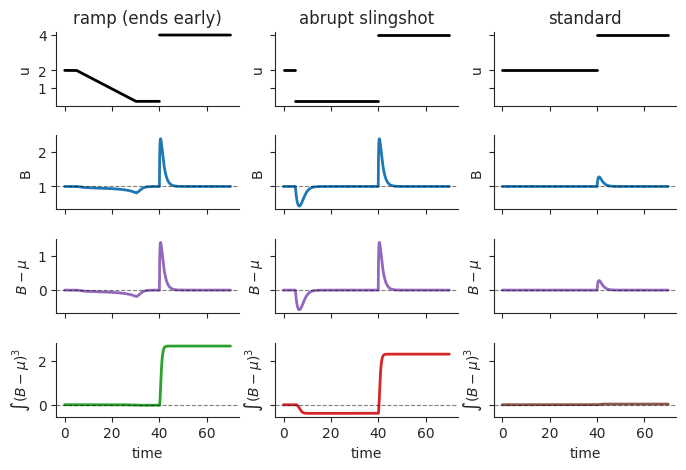

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_4_three_protocols.pdf


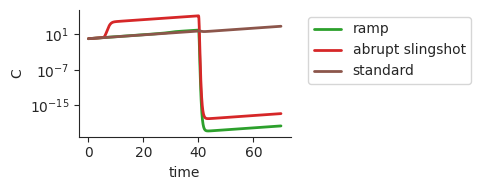

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_case_4_three_protocols_C.pdf
final integral (ramp):       -53.417
final integral (slingshot): -46.051
final integral (standard):   -0.577


In [11]:
# 3-protocol comparison: ramp, abrupt slingshot, standard
t1, t2, t_end = 5.0, 40.0, 70.0
t_ramp_end = t2 - 10.0
c1, c2, mu = 0.1, 20, 1
C0 = 1.0
A0, B0 = 2.0, 1.0
slingshot_u = 0.25


def integrate_C_cubic(t, B):
    def f(tt, C):
        B_t = np.interp(tt, t, B)
        return C[0] * (c1 - c2 * (B_t - mu) ** 3)
        # return C[0] * (c1 - c2 * (B_t - mu))
    sol = solve_ivp(f, [t[0], t[-1]], [C0], t_eval=t,
                    max_step=0.05, rtol=1e-8, atol=1e-10)
    return sol.y[0]


# ── Inputs ──────────────────────────────────────────────────────────
def u_of_t_ramp(tt):
    if tt < t1: return 2.0
    if tt < t_ramp_end: return 2.0 + (slingshot_u - 2.0) * (tt - t1) / (t_ramp_end - t1)
    if tt < t2: return slingshot_u
    return 4.0

def u_of_t_slingshot(tt):
    if tt < t1: return 2.0
    if tt < t2: return slingshot_u
    return 4.0

def u_of_t_standard(tt):
    # no slingshot: hold at 2 until t2, then jump to 4
    if tt < t2: return 2.0
    return 4.0


t = np.linspace(0, t_end, 6000)


def simulate(u_fn):
    sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                    args=(u_fn,), max_step=0.05,
                    rtol=1e-8, atol=1e-10)
    B = sol.y[1]
    C = integrate_C_cubic(t, B)
    return B, C


B_ramp,        C_ramp        = simulate(u_of_t_ramp)
B_slingshot,  C_slingshot  = simulate(u_of_t_slingshot)
B_standard,    C_standard    = simulate(u_of_t_standard)

from scipy.integrate import cumulative_trapezoid
I_ramp       = cumulative_trapezoid((B_ramp       - mu) ** 3, t, initial=0.0)
I_slingshot = cumulative_trapezoid((B_slingshot - mu) ** 3, t, initial=0.0)
I_standard   = cumulative_trapezoid((B_standard   - mu) ** 3, t, initial=0.0)


# ── Top figure: u, B, B-mu, integral over 3 protocols (4 rows × 3 cols) ──
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(8, 5),
                         sharex=True, sharey='row',
                         gridspec_kw={'hspace': 0.4})

lw = 2

protocols = [
    ('ramp (ends early)',      u_of_t_ramp,        B_ramp,       I_ramp,       [(0, t_end)]),
    ('abrupt slingshot',   u_of_t_slingshot,  B_slingshot, I_slingshot, [(0, t1), (t1, t2), (t2, t_end)]),
    ('standard',               u_of_t_standard,    B_standard,   I_standard,   [(0, t2), (t2, t_end)]),
]

for col, (title, u_fn, B_vec, I_vec, segments) in enumerate(protocols):
    # Row 0: u
    ax = axes[0, col]
    if title.startswith('ramp'):
        u_vals = np.array([u_fn(tt) for tt in t])
        u_plot = u_vals.copy()
        u_plot[np.isclose(t, t2, atol=t[1] - t[0])] = np.nan
        ax.plot(t, u_plot, lw=lw, color='k')
    else:
        for seg in segments:
            ax.plot(seg,
                    [u_fn(seg[0] + 0.01), u_fn(seg[1] - 0.01)],
                    lw=lw, color='k')
    ax.set_ylabel('u')
    ax.set_yticks([1, 2, 4])
    ax.set_ylim(bottom=0)
    ax.set_title(title)

    # Row 1: B
    axes[1, col].plot(t, B_vec, lw=lw, color='C0')
    axes[1, col].axhline(mu, color='k', linestyle='--', lw=0.8, alpha=0.5)
    axes[1, col].set_ylabel('B')

    # Row 2: B - mu
    axes[2, col].plot(t, B_vec - mu, lw=lw, color='C4')
    axes[2, col].axhline(0, color='k', linestyle='--', lw=0.8, alpha=0.5)
    axes[2, col].set_ylabel(r'$B - \mu$')

    # Row 3: cumulative integral of (B-mu)^3
    axes[3, col].plot(t, I_vec, lw=lw, color=['C2', 'C3', 'C5'][col])
    axes[3, col].axhline(0, color='k', linestyle='--', lw=0.8, alpha=0.5)
    axes[3, col].set_ylabel(r'$\int (B-\mu)^3$')
    axes[3, col].set_xlabel('time')

for ax in axes.flatten():
    sns.despine(ax=ax)

plt.show()
save_fig(fig, 'figure5_old_case4_three_protocols.pdf')


# ── Bottom figure: all 3 cancer trajectories overlaid ───────────────
fig_C, ax = plt.subplots(figsize=(5, 2))
ax.plot(t, C_ramp,       lw=lw, color='C2', label='ramp')
ax.plot(t, C_slingshot, lw=lw, color='C3', label='abrupt slingshot')
ax.plot(t, C_standard,   lw=lw, color='C5', label='standard')
ax.set_xlabel('time')
ax.set_ylabel('C')
ax.set_yscale('log')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine(ax=ax)

plt.tight_layout()
plt.show()
save_fig(fig_C, 'figure5_old_case4_three_protocols_C.pdf')

print(f"final integral (ramp):       {-c2 * I_ramp[-1]:.3f}")
print(f"final integral (slingshot): {-c2 * I_slingshot[-1]:.3f}")
print(f"final integral (standard):   {-c2 * I_standard[-1]:.3f}")


## Parameter scans: slingshot robustness to IFFL parameters (type-1 IFFL + cancer)
*(from `figure_iffl_v2.ipynb`, formerly `figure3_v2.ipynb`)*

$$
\frac{dx}{dt} = \alpha\,u - \delta\,x \qquad
\frac{dy}{dt} = \beta\,u - \gamma\,x\,y \qquad
\frac{dC}{dt} = C\bigl(c_1 - c_2\,\max(y_{ss} - y,\,0)\bigr)
$$

Note the killing kernel here is $(y_{ss} - y)^+$ (cancer is killed when the output dips **below** steady state), unlike the main figure's $(B - \mu)$ kernels.

Contents: slingshot example, single-parameter scan (×2 / ×½ of each of α, δ, β, γ), pairwise parameter scan, and a heatmap of the slingshot benefit over (prep value × ramp duration).

In [ ]:
"""Setup: imports, shared parameters, IFFL + Cancer ODE, simulation helpers."""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import sys
sys.path.insert(0, '../src')
from rpa_control.style import set_style
from rpa_control.paths import save_fig

set_style()
plt.rcParams['text.usetex'] = False

# ── Plotting helpers ──────────────────────────────────────────────────

def clean_ax(ax):
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

# ── Shared IFFL parameters ────────────────────────────────────────────

PARAMS = dict(alpha=1.0, delta=1.0, beta=1.0, gamma=1.0)

# Cancer kinetics (same convention as rpa_model_class)
C1_CANCER = 0.05   # baseline growth rate
C2_CANCER = 1.0    # kill rate when y is below y_ss

def y_ss_val(p=PARAMS):
    """Analytic steady state of y (independent of u)."""
    return p['beta'] * p['delta'] / (p['gamma'] * p['alpha'])

def steady_state(u, p=PARAMS):
    """Return (x_ss, y_ss) for a given input u."""
    x_ss = p['alpha'] * u / p['delta']
    return x_ss, y_ss_val(p)

# ── IFFL + Cancer ODE ─────────────────────────────────────────────────

Y_SS = y_ss_val()  # fixed at baseline params

def iffl_cancer_rhs(t, state, u, p=PARAMS):
    """
    Right-hand side of the augmented IFFL system.

    state : [x, y, C]
    u     : current input (scalar or callable(t))
    """
    x, y, C = state
    u_val = u(t) if callable(u) else u
    dx = p['alpha'] * u_val - p['delta'] * x
    dy = p['beta']  * u_val - p['gamma'] * x * y
    dC = C * (C1_CANCER - C2_CANCER * max(Y_SS - y, 0.0))
    return [dx, dy, dC]

# ── Simulation helper ─────────────────────────────────────────────────

def simulate(u, t_span, y0=None, n_pts=1000, p=PARAMS):
    """
    Integrate the IFFL+Cancer system.

    u     : constant float or callable(t)
    t_span: (t_start, t_end)
    y0    : [x0, y0, C0]; if None uses SS at constant u with C=1
    """
    if y0 is None:
        u0 = u(t_span[0]) if callable(u) else u
        x0, y0_ss = steady_state(u0, p)
        y0 = [x0, y0_ss, 1.0]   # Cancer starts at 1
    t_eval = np.linspace(*t_span, n_pts)
    sol = solve_ivp(
        lambda t, s: iffl_cancer_rhs(t, s, u, p),
        t_span, y0, t_eval=t_eval,
        method='Radau', rtol=1e-9, atol=1e-11, dense_output=True)
    return sol

print(f"y_ss = {Y_SS:.4f}  (independent of u — RPA confirmed)")
print(f"Cancer: grows at c1={C1_CANCER}, decays at rate c2={C2_CANCER} when y < y_ss")


y_ss = 1.0000  (independent of u — RPA confirmed)
Cancer: grows at c1=0.05, decays at rate c2=1.0 when y < y_ss


In [ ]:
def slingshot_strategy(params, parameter, baseline_value, prep_value, treat_value,
                           u_base=1.0, ramp_duration=20.0, t_post=30.0,
                           C0=1.0, n_pts=2000, use_ramp=True):
    """
    Two-stage slingshot + treatment for the IFFL+Cancer model.

    Stage 1 — preparation: if `use_ramp` is True, linearly ramp `parameter` 
              from baseline_value to prep_value over ramp_duration. If False,
              start directly at the prep_value steady-state and hold for ramp_duration.
    Stage 2 — treatment: abruptly switch `parameter` to treat_value and
              integrate for t_post time units.

    A control trajectory is also computed: the baseline ODE runs for the
    full ramp_duration, then the same abrupt treatment is applied.

    Parameters
    ----------
    params         : kinetic parameter dict (e.g. PARAMS); acts as the model
    parameter      : name of the parameter to vary — 'u' or any key in params
    baseline_value : starting value (system begins at its SS here)
    prep_value     : value ramped to (or started at) during Stage 1
    treat_value    : value applied abruptly in Stage 2
    u_base         : nominal input signal (used when parameter != 'u')
    ramp_duration  : length of Stage 1
    t_post         : length of Stage 2
    C0             : initial Cancer value (default 1.0)
    n_pts          : total number of time points across both stages
    use_ramp       : bool, if True, ramp from baseline to prep_value. If False, 
                     start directly at prep_value steady-state.

    Returns
    -------
    dict with keys:
        t_sling, y_sling   : full slingshot trajectory (3 × n array)
        t_ctrl, y_ctrl   : control trajectory
        param_arr        : parameter value at every slingshot time point
        t_switch         : time of the ramp-to-treatment switch (= ramp_duration)
        y_ss             : homeostatic steady-state of y at baseline params
        parameter, baseline_value, prep_value, treat_value
    """
    # ── helpers ──────────────────────────────────────────────────────
    def resolve(param_val):
        """Return (u_val, p_eff) for the given value of `parameter`."""
        if parameter == 'u':
            return param_val, params
        return u_base, {**params, parameter: param_val}

    def make_rhs(param_val):
        u_val, p_eff = resolve(param_val)
        return lambda t, s: iffl_cancer_rhs(t, s, u_val, p_eff)

    # ── baseline steady state ─────────────────────────────────────────
    u0, p0     = resolve(baseline_value)
    x0, _      = steady_state(u0, p0)
    y_ss_base  = y_ss_val(p0)            # reference for cancer dynamics
    state0     = [x0, y_ss_base, C0]
    
    # ── prep steady state (if bypassing ramp) ─────────────────────────
    if not use_ramp:
        u_prep, p_prep = resolve(prep_value)
        x_prep, _      = steady_state(u_prep, p_prep)
        state0_sling    = [x_prep, y_ss_val(p_prep), C0]
    else:
        state0_sling    = state0

    n_ramp = max(int(n_pts * ramp_duration / (ramp_duration + t_post)), 100)
    n_post = max(n_pts - n_ramp, 100)

    # ── Stage 1: ramp / wait (slingshot) ─────────────────────────────
    def ramp_val(t):
        if use_ramp:
            frac = min(t / ramp_duration, 1.0)
            return baseline_value + (prep_value - baseline_value) * frac
        return prep_value

    def rhs_ramp(t, s):
        u_val, p_eff = resolve(ramp_val(t))
        return iffl_cancer_rhs(t, s, u_val, p_eff)

    t_ramp_arr = np.linspace(0, ramp_duration, n_ramp)
    sol_ramp   = solve_ivp(rhs_ramp, (0, ramp_duration), state0_sling,
                           t_eval=t_ramp_arr, method='Radau', rtol=1e-9, atol=1e-11)

    # ── Stage 2: treatment (slingshot) ──────────────────────────────
    # FIX: Integrate from ramp_duration to match the control trajectory timeframe
    t_post_arr = np.linspace(ramp_duration, ramp_duration + t_post, n_post)
    sol_treat  = solve_ivp(make_rhs(treat_value), (ramp_duration, ramp_duration + t_post), sol_ramp.y[:, -1],
                           t_eval=t_post_arr, method='Radau', rtol=1e-9, atol=1e-11)

    # ── Control: baseline ODE during ramp, then treatment ───────────
    sol_ctrl_ramp  = solve_ivp(make_rhs(baseline_value), (0, ramp_duration), state0,
                                t_eval=t_ramp_arr, method='Radau', rtol=1e-9, atol=1e-11)

    t_ctrl_post    = np.linspace(ramp_duration, ramp_duration + t_post, n_post)
    sol_ctrl_treat = solve_ivp(make_rhs(treat_value),
                                (ramp_duration, ramp_duration + t_post),
                                sol_ctrl_ramp.y[:, -1],
                                t_eval=t_ctrl_post, method='Radau', rtol=1e-9, atol=1e-11)

    t_ctrl = np.concatenate([sol_ctrl_ramp.t, sol_ctrl_treat.t[1:]])
    y_ctrl = np.concatenate([sol_ctrl_ramp.y, sol_ctrl_treat.y[:, 1:]], axis=1)

    # ── Combine slingshot trajectory ─────────────────────────────────
    # FIX: No longer artificially shifting sol_treat.t since we fixed the integration timeframe
    t_sling    = np.concatenate([sol_ramp.t, sol_treat.t[1:]])
    y_sling    = np.concatenate([sol_ramp.y, sol_treat.y[:, 1:]], axis=1)
    
    param_arr = np.concatenate([
        np.array([ramp_val(t) for t in sol_ramp.t]),
        np.full(len(sol_treat.t) - 1, treat_value),
    ])

    return dict(
        t_sling=t_sling, y_sling=y_sling,
        t_ctrl=t_ctrl, y_ctrl=y_ctrl,
        param_arr=param_arr,
        t_switch=ramp_duration,
        y_ss=y_ss_base,
        parameter=parameter,
        baseline_value=baseline_value,
        prep_value=prep_value,
        treat_value=treat_value,
    )

In [ ]:
def plot_slingshot(res):
    """Plot y(t) for a slingshot result."""

    TREAT_COLOR = 'lightgray'
    SLINGSHOT_COLOR = 'green'
    CONTROL_COLOR = 'grey'

    t_sw   = res['t_switch']
    t_end  = res['t_sling'][-1]

    # Create a single plot instead of 3
    fig, ax = plt.subplots(figsize=(9, 3.5))

    ax.axvspan(t_sw, t_end, color=TREAT_COLOR, alpha=0.4, lw=0)
    # ax.axvline(t_sw, color='k', ls=':', lw=0.9, alpha=0.6)
    clean_ax(ax)

    # ── y(t) ─────────────────────────────────────────────────────────
    ax.plot(res['t_sling'], res['y_sling'][1], color=SLINGSHOT_COLOR, lw=1.8)
    ax.plot(res['t_ctrl'], res['y_ctrl'][1], color=CONTROL_COLOR,    lw=1.8, ls='--')
    ax.axhline(res['y_ss'], color='k', ls='--', lw=1)
    
    ax.set_ylabel('O')
    ax.set_xlabel('time')

    # Start x-axis 2 timesteps before treatment
    ax.set_xlim(left=t_sw - 10, right=t_end)
    ax.set_ylim(0.9, 1.6)
    ax.set_xticks([10.0, 15.0, 20.0])
    ax.set_xticklabels([10, 15, 20])

    # fig.suptitle(
    #     f"Slingshot — {res['parameter']}: "
    #     f"{res['baseline_value']:.3g} → {res['prep_value']:.3g} → {res['treat_value']:.3g}",
    #     fontsize=10)
        
    plt.tight_layout()
    save_fig(fig, 'figure5_old_param_scan_slingshot_output.pdf')
    return fig

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_sensitization_output.pdf


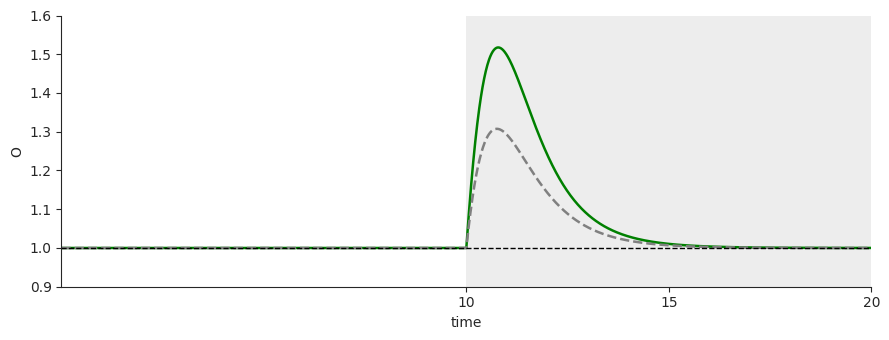

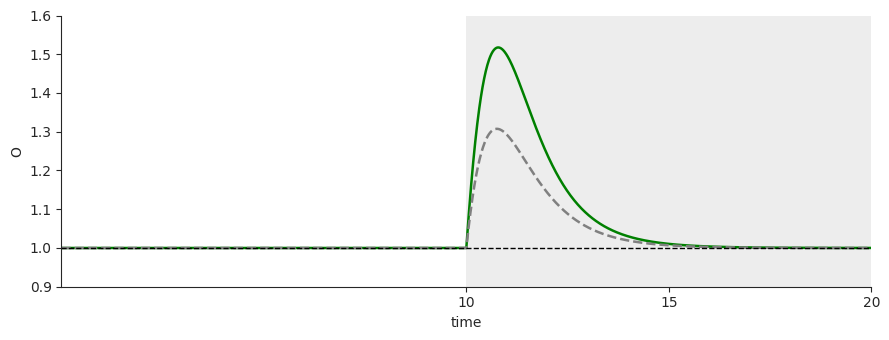

In [ ]:
# Example
res = slingshot_strategy(
    PARAMS,
    parameter='u',
    baseline_value=1.0,
    prep_value=0.5,
    treat_value=2.0,
    ramp_duration=10.0,
    t_post=10.0,
    use_ramp=False,  # Start directly at prep_value steady-state
)
plot_slingshot(res)


baseline:  ratio=0.663
alpha ×2.0:  y_min sling=0.2096  ctrl=0.3559  ratio=0.589
alpha ×0.5:  y_min sling=1.2957  ctrl=1.7137  ratio=0.756
delta ×2.0:  y_min sling=1.5320  ctrl=1.8240  ratio=0.840
delta ×0.5:  y_min sling=0.1768  ctrl=0.3222  ratio=0.549
beta ×2.0:  y_min sling=1.0439  ctrl=1.5736  ratio=0.663
beta ×0.5:  y_min sling=0.2610  ctrl=0.3934  ratio=0.663
gamma ×2.0:  y_min sling=0.2096  ctrl=0.3559  ratio=0.589
gamma ×0.5:  y_min sling=1.2957  ctrl=1.7137  ratio=0.756


/tmp/ipykernel_1200587/2485494393.py:106: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


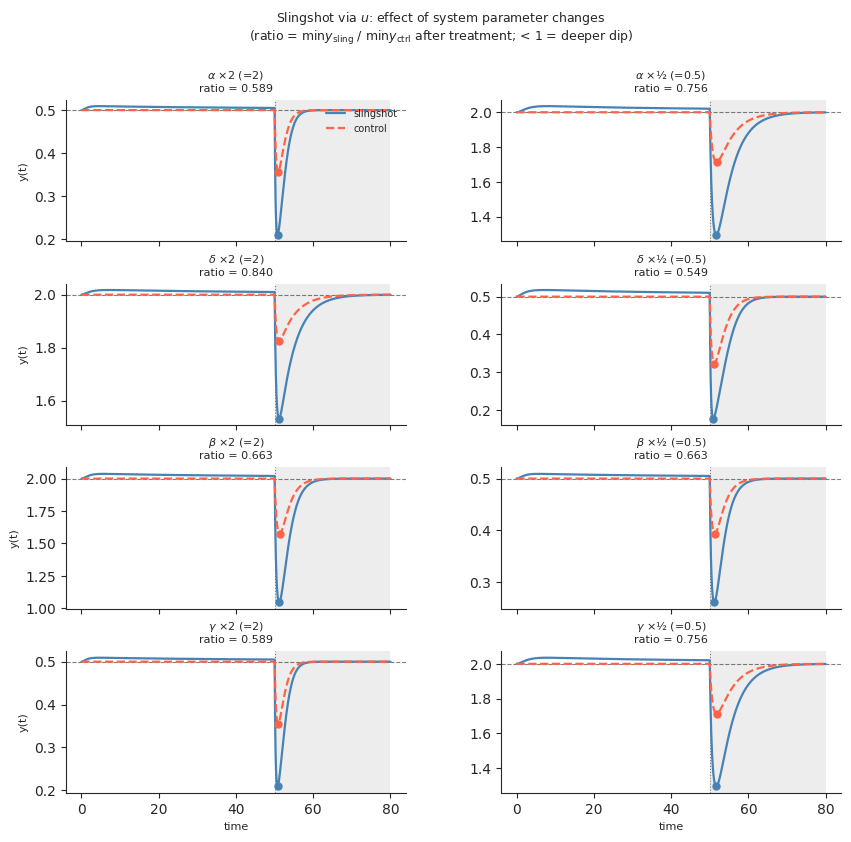

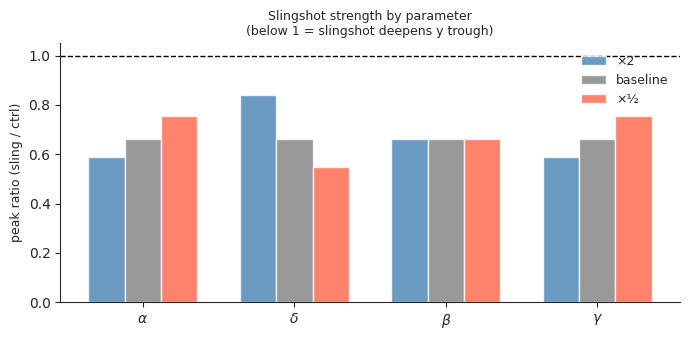

In [20]:
# ── Parameter scan: slingshot across system parameters ────────────
# For each of the 4 IFFL parameters, test x2 and x0.5 of the baseline.
# Slingshot always acts on u (baseline=1→prep=2→treat=0.5).
# Metric: min(y) after treatment switch for slingshot vs control.
# Ratio = y_peak_slingshot / y_peak_control  (< 1 → deeper dip → better)

SYS_PARAMS  = ['alpha', 'delta', 'beta', 'gamma']
FACTORS     = [2.0, 0.5]
FACTOR_LBLS = ['×2', '×½']

RAMP_DUR = 50.0
T_POST   = 30.0

def _compute_ratio(res):
    t_sw   = res['t_switch']
    mask_s = res['t_sling'] >= t_sw
    mask_c = res['t_ctrl'] >= t_sw
    y_min_sling = res['y_sling'][1][mask_s].min()
    y_min_ctrl = res['y_ctrl'][1][mask_c].min()
    return y_min_sling / y_min_ctrl, y_min_sling, y_min_ctrl

# ── Baseline run (original PARAMS, no parameter change) ───────────────
res_base = slingshot_strategy(
    PARAMS,
    parameter='u',
    baseline_value=1.0,
    prep_value=2.0,
    treat_value=0.5,
    ramp_duration=RAMP_DUR,
    t_post=T_POST,
)
ratio_base, _, _ = _compute_ratio(res_base)
print(f"baseline:  ratio={ratio_base:.3f}")

# ── Scan ──────────────────────────────────────────────────────────────
results = {}   # keyed by (param, factor)

for pname in SYS_PARAMS:
    for fac in FACTORS:
        mod_params = {**PARAMS, pname: PARAMS[pname] * fac}
        res = slingshot_strategy(
            mod_params,
            parameter='u',
            baseline_value=1.0,
            prep_value=2.0,
            treat_value=0.5,
            ramp_duration=RAMP_DUR,
            t_post=T_POST,
        )
        ratio, y_min_sling, y_min_ctrl = _compute_ratio(res)
        results[(pname, fac)] = dict(res=res, ratio=ratio,
                                     y_min_sling=y_min_sling,
                                     y_min_ctrl=y_min_ctrl)
        print(f"{pname} ×{fac:.1f}:  y_min sling={y_min_sling:.4f}  ctrl={y_min_ctrl:.4f}  ratio={ratio:.3f}")

# ── Trajectory grid ───────────────────────────────────────────────────
fig, axes = plt.subplots(len(SYS_PARAMS), len(FACTORS),
                         figsize=(10, 9), sharex=True,
                         gridspec_kw={'hspace': 0.30, 'wspace': 0.28})

TREAT_COLOR = 'lightgray'

for row, pname in enumerate(SYS_PARAMS):
    for col, (fac, flbl) in enumerate(zip(FACTORS, FACTOR_LBLS)):
        ax  = axes[row, col]
        d   = results[(pname, fac)]
        res = d['res']
        t_sw = res['t_switch']

        ax.axvspan(t_sw, res['t_sling'][-1], color=TREAT_COLOR, alpha=0.4, lw=0)
        ax.axvline(t_sw, color='k', ls=':', lw=0.8, alpha=0.5)
        ax.axhline(res['y_ss'], color='k', ls='--', lw=0.8, alpha=0.5)

        ax.plot(res['t_sling'], res['y_sling'][1], color='steelblue', lw=1.6, label='slingshot')
        ax.plot(res['t_ctrl'], res['y_ctrl'][1], color='tomato',    lw=1.6, ls='--', label='control')

        # mark the troughs
        mask_s = res['t_sling'] >= t_sw
        mask_c = res['t_ctrl'] >= t_sw
        idx_s  = np.argmin(res['y_sling'][1][mask_s])
        idx_c  = np.argmin(res['y_ctrl'][1][mask_c])
        t_s_min = res['t_sling'][mask_s][idx_s]
        t_c_min = res['t_ctrl'][mask_c][idx_c]
        ax.plot(t_s_min, d['y_min_sling'], 'o', color='steelblue', ms=5, zorder=5)
        ax.plot(t_c_min, d['y_min_ctrl'], 'o', color='tomato',    ms=5, zorder=5)

        param_val = PARAMS[pname] * fac
        ax.set_title(
            rf'$\{pname}$ {flbl} (={param_val:.2g})'
            f'\nratio = {d["ratio"]:.3f}',
            fontsize=8)

        if col == 0:
            ax.set_ylabel('y(t)', fontsize=8)
        if row == len(SYS_PARAMS) - 1:
            ax.set_xlabel('time', fontsize=8)

        clean_ax(ax)

axes[0, 0].legend(fontsize=7, frameon=False, loc='upper right')

fig.suptitle(
    'Slingshot via $u$: effect of system parameter changes\n'
    r'(ratio = $\min y_{\rm sling}$ / $\min y_{\rm ctrl}$ after treatment; < 1 = deeper dip)',
    fontsize=9)
plt.tight_layout()
plt.show()

# ── Summary bar chart ─────────────────────────────────────────────────
fig2, ax2 = plt.subplots(figsize=(7, 3.5))

x_pos  = np.arange(len(SYS_PARAMS))
width  = 0.24
# three bars per group: ×2 | baseline | ×½
offsets = [-1, 0, 1]
bar_specs = [
    (FACTORS[0], FACTOR_LBLS[0], 'steelblue'),
    (None,       'baseline',     'gray'),
    (FACTORS[1], FACTOR_LBLS[1], 'tomato'),
]

for off, (fac, flbl, col) in zip(offsets, bar_specs):
    if fac is None:
        ratios = [ratio_base] * len(SYS_PARAMS)
    else:
        ratios = [results[(p, fac)]['ratio'] for p in SYS_PARAMS]
    ax2.bar(x_pos + off * width, ratios, width, label=flbl, color=col, alpha=0.8)

ax2.axhline(1.0, color='k', ls='--', lw=1.0)
ax2.set_xticks(x_pos)
ax2.set_xticklabels([rf'$\{p}$' for p in SYS_PARAMS], fontsize=10)
ax2.set_ylabel('peak ratio (sling / ctrl)', fontsize=9)
ax2.set_title('Slingshot strength by parameter\n(below 1 = slingshot deepens y trough)', fontsize=9)
ax2.legend(fontsize=9, frameon=False)
clean_ax(ax2)
plt.tight_layout()
plt.show()


alpha×2, beta×2:  sling=0.4191  ctrl=0.7118  ratio=0.589
alpha×½, beta×½:  sling=0.6478  ctrl=0.8569  ratio=0.756
delta×2, beta×½:  sling=0.7660  ctrl=0.9120  ratio=0.840
delta×½, beta×2:  sling=0.3537  ctrl=0.6443  ratio=0.549
gamma×2, beta×2:  sling=0.4191  ctrl=0.7118  ratio=0.589
gamma×½, beta×½:  sling=0.6478  ctrl=0.8569  ratio=0.756


/tmp/ipykernel_1200587/2551941205.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


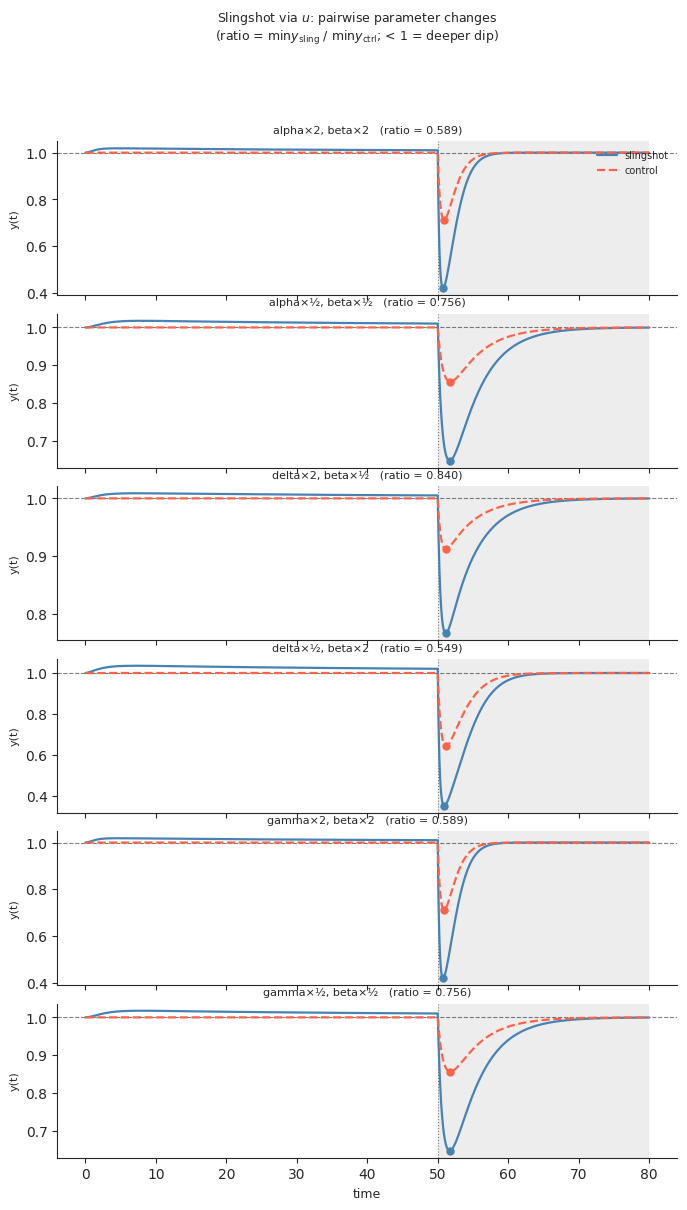

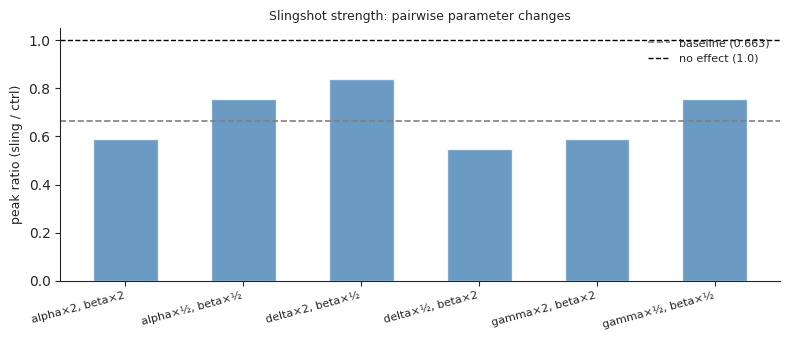

In [ ]:
# ── Pairwise parameter scan ───────────────────────────────────────────
# Each combo modifies two parameters simultaneously; slingshot via u.

COMBOS = [
    ('alpha×2, beta×2',    dict(alpha=2.0, beta=2.0)),
    ('alpha×½, beta×½',    dict(alpha=0.5, beta=0.5)),
    ('delta×2, beta×½',    dict(delta=2.0, beta=0.5)),
    ('delta×½, beta×2',    dict(delta=0.5, beta=2.0)),
    ('gamma×2, beta×2',    dict(gamma=2.0, beta=2.0)),
    ('gamma×½, beta×½',    dict(gamma=0.5, beta=0.5)),
]

combo_results = {}

for label, overrides in COMBOS:
    mod_params = {**PARAMS, **overrides}
    res = slingshot_strategy(
        mod_params,
        parameter='u',
        baseline_value=1.0,
        prep_value=2.0,
        treat_value=0.5,
        ramp_duration=RAMP_DUR,
        t_post=T_POST,
    )
    ratio, y_min_sling, y_min_ctrl = _compute_ratio(res)
    combo_results[label] = dict(res=res, ratio=ratio,
                                y_min_sling=y_min_sling,
                                y_min_ctrl=y_min_ctrl)
    print(f"{label}:  sling={y_min_sling:.4f}  ctrl={y_min_ctrl:.4f}  ratio={ratio:.3f}")

# ── Trajectory grid ───────────────────────────────────────────────────
n_combos = len(COMBOS)
fig, axes = plt.subplots(n_combos, 1, figsize=(8, 2.2 * n_combos), sharex=True,
                         gridspec_kw={'hspace': 0.12})

for ax, (label, _) in zip(axes, COMBOS):
    d   = combo_results[label]
    res = d['res']
    t_sw = res['t_switch']

    ax.axvspan(t_sw, res['t_sling'][-1], color='lightgray', alpha=0.4, lw=0)
    ax.axvline(t_sw, color='k', ls=':', lw=0.8, alpha=0.5)
    ax.axhline(res['y_ss'], color='k', ls='--', lw=0.8, alpha=0.5)

    ax.plot(res['t_sling'], res['y_sling'][1], color='steelblue', lw=1.6, label='slingshot')
    ax.plot(res['t_ctrl'], res['y_ctrl'][1], color='tomato',    lw=1.6, ls='--', label='control')

    mask_s = res['t_sling'] >= t_sw
    mask_c = res['t_ctrl'] >= t_sw
    t_s_min = res['t_sling'][mask_s][np.argmin(res['y_sling'][1][mask_s])]
    t_c_min = res['t_ctrl'][mask_c][np.argmin(res['y_ctrl'][1][mask_c])]
    ax.plot(t_s_min, d['y_min_sling'], 'o', color='steelblue', ms=5, zorder=5)
    ax.plot(t_c_min, d['y_min_ctrl'], 'o', color='tomato',    ms=5, zorder=5)

    ax.set_ylabel('y(t)', fontsize=8)
    ax.set_title(f'{label}   (ratio = {d["ratio"]:.3f})', fontsize=8)
    clean_ax(ax)

axes[0].legend(fontsize=7, frameon=False, loc='upper right')
axes[-1].set_xlabel('time', fontsize=9)
fig.suptitle(
    'Slingshot via $u$: pairwise parameter changes\n'
    r'(ratio = $\min y_{\rm sling}$ / $\min y_{\rm ctrl}$; < 1 = deeper dip)',
    fontsize=9)
plt.tight_layout()
plt.show()

# ── Summary bar chart ─────────────────────────────────────────────────
fig3, ax3 = plt.subplots(figsize=(8, 3.5))

labels  = [lbl for lbl, _ in COMBOS]
ratios  = [combo_results[lbl]['ratio'] for lbl in labels]
x_pos   = np.arange(len(labels))
width   = 0.55

bars = ax3.bar(x_pos, ratios, width, color='steelblue', alpha=0.8)
ax3.axhline(ratio_base, color='gray',  ls='--', lw=1.2, label=f'baseline ({ratio_base:.3f})')
ax3.axhline(1.0,        color='k',     ls='--', lw=1.0, label='no effect (1.0)')

ax3.set_xticks(x_pos)
ax3.set_xticklabels(labels, fontsize=8, rotation=15, ha='right')
ax3.set_ylabel('peak ratio (sling / ctrl)', fontsize=9)
ax3.set_title('Slingshot strength: pairwise parameter changes', fontsize=9)
ax3.legend(fontsize=8, frameon=False)
clean_ax(ax3)
plt.tight_layout()
plt.show()


In [ ]:
def run_heatmap_scan(params, parameter, baseline_value, treat_value,
                     prep_values, ramp_durations,
                     t_post=15.0, C0=1.0, n_pts=600):
    """
    Scan a 2-D grid of (ramp_duration × prep_value) and record
    final Cancer / C0 at the end of each slingshot run.

    Reference: start treatment immediately (no ramp) for t_post time.
    Grid cells below the reference value benefited from slingshot.

    Parameters
    ----------
    params         : kinetic parameter dict
    parameter      : 'u' or any key in params
    baseline_value : starting value of the parameter
    treat_value    : treatment value (Stage 2)
    prep_values    : 1-D array of prep_value candidates (Stage 1 target)
    ramp_durations : 1-D array of ramp duration candidates
    t_post         : fixed treatment duration (same for all grid points)
    C0             : initial Cancer value

    Returns
    -------
    dict with grid, cancer_ref, axes, and metadata
    """
    def resolve(pv):
        if parameter == 'u':
            return pv, params
        return 1.0, {**params, parameter: pv}

    # ── Reference: treat immediately for t_post ───────────────────────
    u0, p0        = resolve(baseline_value)
    x0, y0_ss     = steady_state(u0, p0)
    u_treat, p_tr = resolve(treat_value)

    sol_ref    = solve_ivp(
        lambda t, s: iffl_cancer_rhs(t, s, u_treat, p_tr),
        (0, t_post), [x0, y0_ss, C0],
        method='Radau', rtol=1e-9, atol=1e-11, t_eval=[0, t_post])
    cancer_ref = sol_ref.y[2, -1] / C0

    # ── Grid scan ─────────────────────────────────────────────────────
    n_rd   = len(ramp_durations)
    n_pv   = len(prep_values)
    grid   = np.zeros((n_rd, n_pv))
    n_done = 0

    for i, rd in enumerate(ramp_durations):
        for j, pv in enumerate(prep_values):
            res = slingshot_strategy(
                params, parameter, baseline_value, pv, treat_value,
                ramp_duration=rd, t_post=t_post, C0=C0, n_pts=n_pts)
            grid[i, j] = res['y_sling'][2, -1] / C0
            n_done += 1
        print(f"  {n_done}/{n_rd * n_pv} done", end='\r')
    print(f"  {n_rd * n_pv}/{n_rd * n_pv} done — reference = {cancer_ref:.4f}")

    return dict(
        grid=grid, cancer_ref=cancer_ref,
        prep_values=np.asarray(prep_values),
        ramp_durations=np.asarray(ramp_durations),
        parameter=parameter, t_post=t_post,
        baseline_value=baseline_value, treat_value=treat_value, C0=C0,
    )


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap  # Added for custom colors

def plot_heatmap(scan):
    """
    Heatmap of (Cancer(end)/C0) - reference, centred at 0.
    Green = slingshot reduces final tumour below immediate-treatment baseline.
    Red   = slingshot increases final tumour above baseline.
    White = break-even point (0).
    Star marks the grid point with the greatest improvement.
    """
    grid  = scan['grid']
    pv    = scan['prep_values']
    rd    = scan['ramp_durations']
    ref   = scan['cancer_ref']

    delta = grid - ref          # negative = better than reference

    max_abs = np.abs(delta).max() or 1e-6
    best_i, best_j = np.unravel_index(np.argmin(delta), delta.shape)

    fig, ax = plt.subplots(figsize=(8, 6))

    # --- NEW COLORMAP LOGIC ---
    # Creates a strict Green -> White -> Red gradient
    # Since vmin and vmax are symmetric (-max_abs to max_abs), White will perfectly align with 0
    gwr_cmap = LinearSegmentedColormap.from_list(
        'GreenWhiteRed', ['forestgreen', 'white', 'firebrick']
    )

    im = ax.pcolormesh(pv, rd, delta, cmap=gwr_cmap, shading='auto',
                       vmin=-max_abs, vmax=max_abs)
    
    cb = plt.colorbar(im, ax=ax)
    cb.set_label('Cancer(end)/C0  −  reference', fontsize=9)
    cb.ax.axhline(0, color='k', lw=1.2)

    ax.contour(pv, rd, delta, levels=[0],
               colors='k', linewidths=1.5, linestyles='--')

    ax.scatter(pv[best_j], rd[best_i], marker='*', s=220, color='navy', zorder=5,
               label=(f"best: prep={pv[best_j]:.2f}, ramp={rd[best_i]:.1f}\n"
                      f"Δ Cancer = {delta[best_i, best_j]:+.3f}"))

    ax.set_xlabel(f"{scan['parameter']} during ramp  (prep_value)", fontsize=9)
    ax.set_ylabel('ramp_duration', fontsize=9)
    
    ax.set_title(
        f"Slingshot benefit  |  {scan['parameter']}: "
        f"{scan['baseline_value']:.2g} → prep → {scan['treat_value']:.2g}  |  "
        f"t_post = {scan['t_post']}\n"
        f"Colour = final Cancer − reference ({ref:.3f}).  Black line = break-even.",
        fontsize=9)
        
    ax.legend(fontsize=8, frameon=False, loc='upper left')
    clean_ax(ax) 
    
    plt.tight_layout()
    return fig

  100/100 done — reference = 1.9091


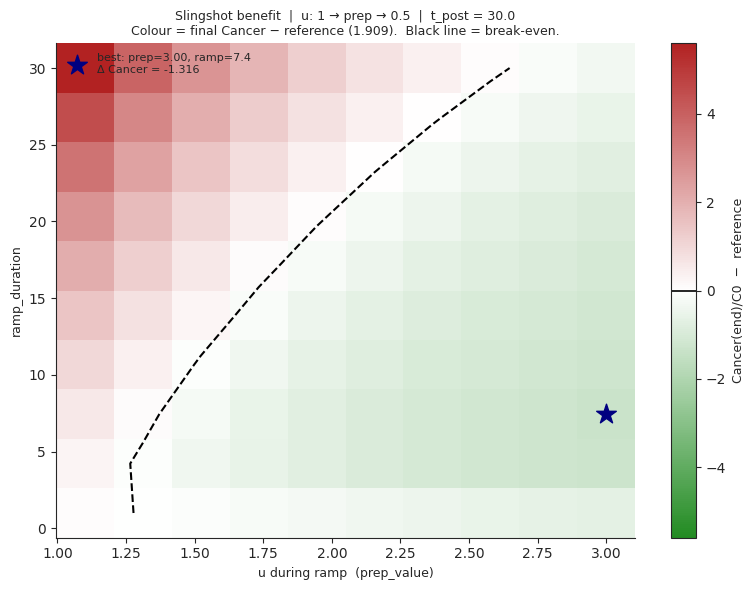

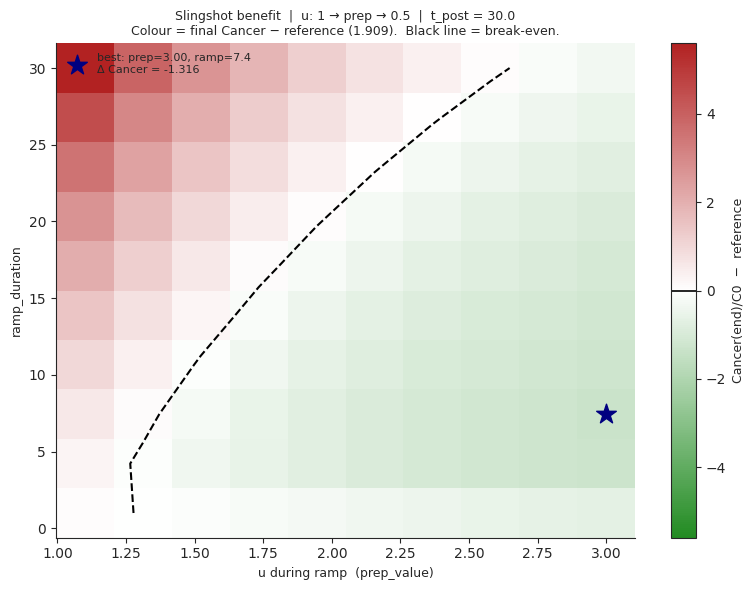

In [ ]:
PREP_VALUES    = np.linspace(1.1, 3.0, 10)   # u values during ramp (above baseline=1)
RAMP_DURATIONS = np.linspace(1, 30, 10)       # ramp durations to explore

scan = run_heatmap_scan(
    PARAMS,
    parameter='u',
    baseline_value=1.0,
    treat_value=0.5,
    prep_values=PREP_VALUES,
    ramp_durations=RAMP_DURATIONS,
    t_post=30.0,
)
plot_heatmap(scan)


## Type-2 IFFL with general parameters + cancer
*(from `figure_iffl_v3.ipynb`, formerly `figure3_v3.ipynb`)*

$$
\frac{dA}{dt} = \beta_1\,u - \alpha_1\,A \qquad
\frac{dB}{dt} = \frac{\beta_2\,u}{A} - \alpha_2\,B \qquad
\frac{dC}{dt} = C\bigl(c_1 - c_2\,\max(B - B_{ss},\,0)\bigr)
$$

Same topology as `fcd_rhs` in the main figure, with free parameters ($B_{ss} = \beta_2\alpha_1 / \alpha_2\beta_1$). Contents: two starting points under the same treatment, gradual vs instant increase of $u$, and a generic slingshot helper that can ramp any parameter.

In [ ]:
"""Setup: imports, shared parameters, IFFL + Cancer ODE, simulation helpers."""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.integrate import solve_ivp
import sys
sys.path.insert(0, '../src')
from rpa_control.style import set_style
from rpa_control.paths import save_fig

set_style()
plt.rcParams['text.usetex'] = False

# ── Plotting helpers ──────────────────────────────────────────────────

def clean_ax(ax):
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

# ── Shared IFFL parameters ────────────────────────────────────────────

PARAMS = dict(beta1=1.0, alpha1=1.0, beta2=1.0, alpha2=1.0)

# Cancer kinetics
C1_CANCER = 0.05   # baseline growth rate
C2_CANCER = 1.0    # kill rate when B is below B_ss

def B_ss_val(p=PARAMS):
    """Analytic steady state of B (independent of u — RPA)."""
    return p['beta2'] * p['alpha1'] / (p['alpha2'] * p['beta1'])

def steady_state(u, p=PARAMS):
    """Return (A_ss, B_ss) for a given input u."""
    A_ss = p['beta1'] * u / p['alpha1']
    return A_ss, B_ss_val(p)

# ── IFFL + Cancer ODE ─────────────────────────────────────────────────

B_SS = B_ss_val()  # fixed at baseline params

def iffl_cancer_rhs(t, state, u, p=PARAMS):
    """
    Right-hand side of the IFFL type-2 + Cancer system.

    state : [A, B, C]
    u     : current input (scalar or callable(t))
    """
    A, B, C = state
    u_val = u(t) if callable(u) else u
    dA = p['beta1'] * u_val - p['alpha1'] * A
    dB = p['beta2'] * u_val / A - p['alpha2'] * B
    dC = C * (C1_CANCER - C2_CANCER * max(B - B_SS, 0.0))
    return [dA, dB, dC]

# ── Simulation helper ─────────────────────────────────────────────────

def simulate(u, t_span, y0=None, n_pts=1000, p=PARAMS):
    """
    Integrate the IFFL+Cancer system.

    u     : constant float or callable(t)
    t_span: (t_start, t_end)
    y0    : [A0, B0, C0]; if None uses SS at constant u with C=1
    """
    if y0 is None:
        u0 = u(t_span[0]) if callable(u) else u
        A0, B0 = steady_state(u0, p)
        y0 = [A0, B0, 1.0]
    t_eval = np.linspace(*t_span, n_pts)
    sol = solve_ivp(
        lambda t, s: iffl_cancer_rhs(t, s, u, p),
        t_span, y0, t_eval=t_eval,
        method='Radau', rtol=1e-9, atol=1e-11, dense_output=True)
    return sol

print(f"B_ss = {B_SS:.4f}  (independent of u — RPA confirmed)")
print(f"Cancer: grows at c1={C1_CANCER}, decays at rate c2={C2_CANCER} when B < B_ss")


B_ss = 1.0000  (independent of u — RPA confirmed)
Cancer: grows at c1=0.05, decays at rate c2=1.0 when B < B_ss


/tmp/ipykernel_1200587/3553330636.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


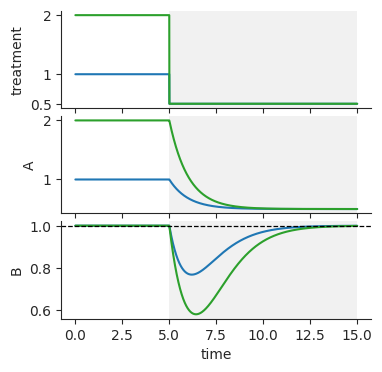

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_two_starting_points.pdf


In [58]:
# Two starting points, same treatment: u → 0.5
# Each trajectory begins at its own SS for 5 time units, then switches.
T_PRE    = 5.0
T_END    = 15.0

cases = [
    dict(u_pre=1.0, color='C0', label='start $u=1$'),
    dict(u_pre=2.0, color='C2', label='start $u=2$'),
]
U_TREAT = 0.5

for c in cases:
    A0, B0 = steady_state(c['u_pre'])
    y0 = [A0, B0, 1.0]
    def u_func(t, u_pre=c['u_pre']):
        return U_TREAT if t >= T_PRE else u_pre
    sol = simulate(u_func, (0, T_END), y0=y0, n_pts=2000)
    c['t'] = sol.t
    c['A'] = sol.y[0]
    c['B'] = sol.y[1]
    c['u_arr'] = np.where(sol.t >= T_PRE, U_TREAT, c['u_pre'])

fig, axes = plt.subplots(3, 1, figsize=(4, 4), sharex=True,
                          gridspec_kw={'hspace': 0.08})

ON_COLOR = 'lightgray'
for ax in axes:
    ax.axvspan(T_PRE, T_END, color=ON_COLOR, alpha=0.3, lw=0)
    clean_ax(ax)

for c in cases:
    axes[0].plot(c['t'], c['u_arr'], color=c['color'], lw=1.5, label=c['label'])
    axes[1].plot(c['t'], c['A'],     color=c['color'], lw=1.5)
    axes[2].plot(c['t'], c['B'],     color=c['color'], lw=1.5)

axes[2].axhline(B_SS, color='k', ls='--', lw=0.9, label=f'$B_{{ss}}={B_SS:.2f}$')
# axes[2].legend(fontsize=8, frameon=False)

axes[0].set_ylabel('treatment')
axes[0].set_yticks([0.5, 1.0, 2.0])
axes[0].set_yticklabels(['0.5', '1', '2'])
axes[1].set_ylabel('A')
axes[2].set_ylabel('B')
axes[2].set_xlabel('time')

# axes[0].legend(fontsize=8, frameon=False)
# axes[0].set_title(f'Two starting points, same treatment u → {U_TREAT}', fontsize=9)
plt.tight_layout()
plt.show()

save_fig(fig, 'figure5_old_type2_two_starting_points.pdf')


/tmp/ipykernel_1200587/2323034594.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


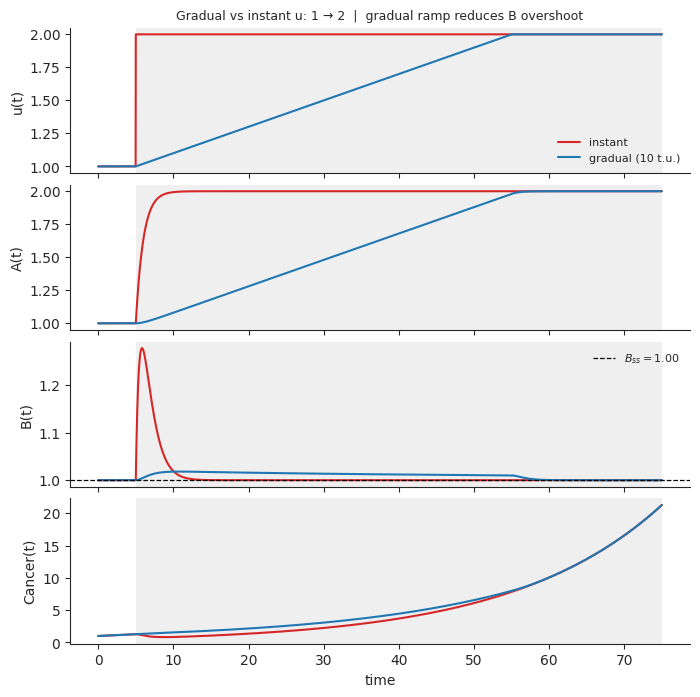

In [ ]:
# Gradual vs instant u: 1 → 2
# Gradual ramp mitigates the transient overshoot in B.
T_PRE  = 5.0
T_RAMP = 50.0
T_POST = 20.0
T_END  = T_PRE + T_RAMP + T_POST

U_START = 1.0
U_END   = 2.0

A0, B0 = steady_state(U_START)
y0 = [A0, B0, 1.0]

def u_instant(t):
    return U_END if t >= T_PRE else U_START

def u_gradual(t):
    if t < T_PRE:
        return U_START
    elif t < T_PRE + T_RAMP:
        return U_START + (U_END - U_START) * (t - T_PRE) / T_RAMP
    else:
        return U_END

cases = [
    dict(u_func=u_instant, color='C3', label='instant', ls='-'),
    dict(u_func=u_gradual, color='C0', label='gradual (10 t.u.)', ls='-'),
]

for c in cases:
    sol = simulate(c['u_func'], (0, T_END), y0=y0, n_pts=3000)
    c['t'] = sol.t
    c['A'] = sol.y[0]
    c['B'] = sol.y[1]
    c['C'] = sol.y[2]
    c['u_arr'] = np.array([c['u_func'](tt) for tt in sol.t])
    INTEG_WINDOW = 70.0
    mask = (c['t'] >= T_PRE) & (c['t'] <= T_PRE + INTEG_WINDOW)
    c['integral_B'] = np.trapezoid((c['B'] - B_SS)[mask], c['t'][mask])

fig, axes = plt.subplots(4, 1, figsize=(8, 8), sharex=True,
                          gridspec_kw={'hspace': 0.08})

for ax in axes:
    ax.axvspan(T_PRE, T_END, color='lightgray', alpha=0.35, lw=0)
    clean_ax(ax)

for c in cases:
    axes[0].plot(c['t'], c['u_arr'], color=c['color'], lw=1.5, label=c['label'])
    axes[1].plot(c['t'], c['A'],     color=c['color'], lw=1.5)
    axes[2].plot(c['t'], c['B'],     color=c['color'], lw=1.5)
    axes[3].plot(c['t'], c['C'],     color=c['color'], lw=1.5)

axes[2].axhline(B_SS, color='k', ls='--', lw=0.9, label=f'$B_{{ss}}={B_SS:.2f}$')

# Annotate integrals on the B panel
# annot_lines = [rf"$\\int_{{0}}^{{10}}(B-B_{{{{ss}}}})\\,dt$ = {c['integral_B']:+.6f}  ({c['label']})" for c in cases]
# axes[2].text(0.02, 0.97, '\n'.join(annot_lines),
#              transform=axes[2].transAxes, fontsize=8,
#              va='top', ha='left', family='monospace',
#              bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', boxstyle='round,pad=0.3'))
axes[2].legend(fontsize=8, frameon=False)

axes[0].set_ylabel('u(t)')
axes[1].set_ylabel('A(t)')
axes[2].set_ylabel('B(t)')
axes[3].set_ylabel('Cancer(t)')
axes[3].set_xlabel('time')

axes[0].legend(fontsize=8, frameon=False)
axes[0].set_title('Gradual vs instant u: 1 → 2  |  gradual ramp reduces B overshoot', fontsize=9)
plt.tight_layout()
plt.show()


In [28]:
def slingshot_strategy(params, parameter, baseline_value, prep_value, treat_value,
                            u_base=1.0, ramp_duration=20.0, t_post=30.0,
                            C0=1.0, n_pts=2000):
    """
    Two-stage slingshot + treatment for the IFFL+Cancer model.

    Stage 1 — preparation: linearly ramp `parameter` from baseline_value to
              prep_value over ramp_duration time units.
    Stage 2 — treatment: abruptly switch `parameter` to treat_value and
              integrate for t_post time units.

    A control trajectory is also computed: the baseline ODE runs for the
    full ramp_duration, then the same abrupt treatment is applied.

    Returns
    -------
    dict with keys:
        t_sling, y_sling   : full slingshot trajectory (3 × n array)
        t_ctrl, y_ctrl   : control trajectory
        param_arr        : parameter value at every slingshot time point
        t_switch         : time of the ramp-to-treatment switch (= ramp_duration)
        B_ss             : homeostatic steady-state of B at baseline params
        parameter, baseline_value, prep_value, treat_value
    """
    def resolve(param_val):
        """Return (u_val, p_eff) for the given value of `parameter`."""
        if parameter == 'u':
            return param_val, params
        return u_base, {**params, parameter: param_val}

    def make_rhs(param_val):
        u_val, p_eff = resolve(param_val)
        return lambda t, s: iffl_cancer_rhs(t, s, u_val, p_eff)

    # ── baseline steady state ─────────────────────────────────────────
    u0, p0    = resolve(baseline_value)
    A0, _     = steady_state(u0, p0)
    B_ss_base = B_ss_val(p0)
    state0    = [A0, B_ss_base, C0]

    n_ramp = max(int(n_pts * ramp_duration / (ramp_duration + t_post)), 100)
    n_post = max(n_pts - n_ramp, 100)

    # ── Stage 1: ramp (slingshot) ────────────────────────────────────
    def ramp_val(t):
        frac = min(t / ramp_duration, 1.0)
        return baseline_value + (prep_value - baseline_value) * frac

    def rhs_ramp(t, s):
        u_val, p_eff = resolve(ramp_val(t))
        return iffl_cancer_rhs(t, s, u_val, p_eff)

    t_ramp_arr = np.linspace(0, ramp_duration, n_ramp)
    sol_ramp   = solve_ivp(rhs_ramp, (0, ramp_duration), state0,
                            t_eval=t_ramp_arr, method='Radau', rtol=1e-9, atol=1e-11)

    # ── Stage 2: treatment (slingshot) ──────────────────────────────
    t_post_arr = np.linspace(ramp_duration, ramp_duration + t_post, n_post)
    sol_treat  = solve_ivp(make_rhs(treat_value),
                            (ramp_duration, ramp_duration + t_post),
                            sol_ramp.y[:, -1],
                            t_eval=t_post_arr, method='Radau', rtol=1e-9, atol=1e-11)

    # ── Control: baseline ODE during ramp, then treatment ────────────
    sol_ctrl_ramp  = solve_ivp(make_rhs(baseline_value), (0, ramp_duration), state0,
                                t_eval=t_ramp_arr, method='Radau', rtol=1e-9, atol=1e-11)
    t_ctrl_post    = np.linspace(ramp_duration, ramp_duration + t_post, n_post)
    sol_ctrl_treat = solve_ivp(make_rhs(treat_value),
                                (ramp_duration, ramp_duration + t_post),
                                sol_ctrl_ramp.y[:, -1],
                                t_eval=t_ctrl_post, method='Radau', rtol=1e-9, atol=1e-11)

    t_ctrl = np.concatenate([sol_ctrl_ramp.t, sol_ctrl_treat.t[1:]])
    y_ctrl = np.concatenate([sol_ctrl_ramp.y, sol_ctrl_treat.y[:, 1:]], axis=1)

    t_sling = np.concatenate([sol_ramp.t, sol_treat.t[1:]])
    y_sling = np.concatenate([sol_ramp.y, sol_treat.y[:, 1:]], axis=1)

    param_arr = np.concatenate([
        np.array([ramp_val(t) for t in sol_ramp.t]),
        np.full(len(sol_treat.t) - 1, treat_value),
    ])

    return dict(
        t_sling=t_sling, y_sling=y_sling,
        t_ctrl=t_ctrl, y_ctrl=y_ctrl,
        param_arr=param_arr,
        t_switch=ramp_duration,
        B_ss=B_ss_base,
        parameter=parameter,
        baseline_value=baseline_value,
        prep_value=prep_value,
        treat_value=treat_value,
    )


In [29]:
def plot_slingshot(res):
    """Plot B(t), Cancer(t), and parameter(t) for a slingshot result."""

    TREAT_COLOR = 'lightgray'

    t_sw  = res['t_switch']
    t_end = res['t_sling'][-1]

    fig, (ax_B, ax_C, ax_p) = plt.subplots(
        3, 1, figsize=(9, 7), sharex=True,
        gridspec_kw={'height_ratios': [2, 2, 1], 'hspace': 0.08})

    for ax in (ax_B, ax_C, ax_p):
        ax.axvspan(t_sw, t_end, color=TREAT_COLOR, alpha=0.4, lw=0)
        ax.axvline(t_sw, color='k', ls=':', lw=0.9, alpha=0.6)
        clean_ax(ax)

    # ── B(t) ──────────────────────────────────────────────────────────
    ax_B.plot(res['t_sling'], res['y_sling'][1], color='steelblue', lw=1.8, label='slingshot')
    ax_B.plot(res['t_ctrl'], res['y_ctrl'][1], color='tomato',    lw=1.8, ls='--', label='control')
    ax_B.axhline(res['B_ss'], color='k', ls='--', lw=1,
                 label=f"$B_{{ss}} = {res['B_ss']:.2f}$")
    ax_B.set_ylabel('B(t)')
    ax_B.legend(handles=[
        plt.Line2D([0],[0], color='steelblue', lw=1.8, label='slingshot'),
        plt.Line2D([0],[0], color='tomato',    lw=1.8, ls='--', label='control'),
        plt.Line2D([0],[0], color='k',         lw=1,   ls='--',
                   label=f"$B_{{ss}}={res['B_ss']:.2f}$"),
        mpatches.Patch(facecolor=TREAT_COLOR, alpha=0.6,
                       label=f"treat → {res['treat_value']:.3g}"),
    ], fontsize=8, frameon=False)

    # ── Cancer(t) ─────────────────────────────────────────────────────
    c_s = res['y_sling'][2]
    c_c = res['y_ctrl'][2]

    ax_C.plot(res['t_sling'], c_s, color='steelblue', lw=1.8)
    ax_C.plot(res['t_ctrl'], c_c, color='tomato',    lw=1.8, ls='--')
    ax_C.set_ylabel('Cancer(t)')

    n_treat = np.searchsorted(res['t_sling'], t_sw, side='right')
    stats = ('slingshot:  min=%.3f  final=%.3f\n'
             'control:     min=%.3f  final=%.3f') % (
             c_s[n_treat:].min(), c_s[-1], c_c[n_treat:].min(), c_c[-1])
    ax_C.text(0.02, 0.97, stats, transform=ax_C.transAxes,
              fontsize=7.5, ha='left', va='top', family='monospace',
              bbox=dict(facecolor='white', alpha=0.75, edgecolor='none',
                        boxstyle='round,pad=0.3'))

    # ── parameter(t) ──────────────────────────────────────────────────
    p_ctrl = np.where(res['t_ctrl'] <= t_sw,
                      res['baseline_value'], res['treat_value'])
    ax_p.plot(res['t_sling'], res['param_arr'], color='steelblue', lw=1.5)
    ax_p.plot(res['t_ctrl'], p_ctrl,           color='tomato',    lw=1.5, ls='--')
    ax_p.set_ylabel(res['parameter'])
    ax_p.set_xlabel('time')
    yticks = sorted({res['baseline_value'], res['prep_value'], res['treat_value']})
    ax_p.set_yticks(yticks)
    ax_p.set_yticklabels([f"{v:.3g}" for v in yticks], fontsize=7)

    fig.suptitle(
        f"Slingshot — {res['parameter']}: "
        f"{res['baseline_value']:.3g} → {res['prep_value']:.3g} → {res['treat_value']:.3g}",
        fontsize=10)
    plt.tight_layout()
    return fig


/tmp/ipykernel_1200587/1327780726.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


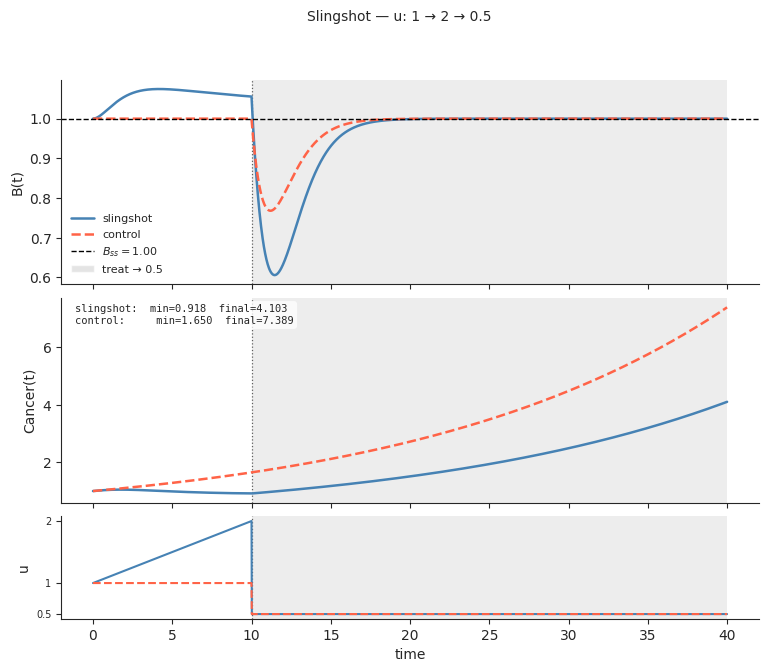

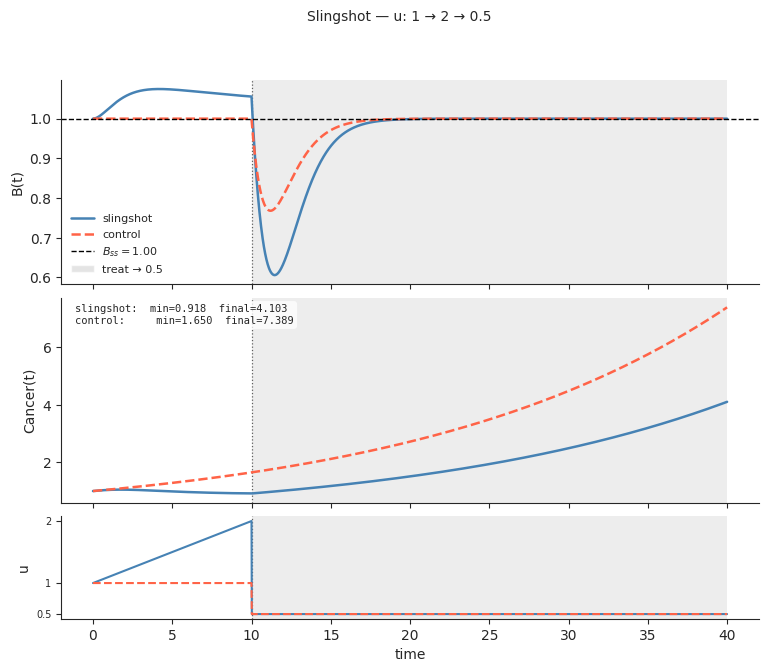

In [30]:
# Example
res = slingshot_strategy(
    PARAMS,
    parameter='u',
    baseline_value=1.0,
    prep_value=2.0,
    treat_value=0.5,
    ramp_duration=10.0,
    t_post=30.0,
)
plot_slingshot(res)
